# Лабораторно-практичне заняття №6
## Побудова маршруту: алгоритми Дейкстри та A* на реальній вуличній мережі

**Перед початком роботи:** меню **File → Save a copy in Drive** — працюйте у своїй копії.
Потім у Блоці 1 вкажіть свій `STUDENT_NUMBER` і запустіть усе кнопкою **▶ Run all**.

Дані — пішохідна мережа району університету з OpenStreetMap
(© учасники OpenStreetMap, ліцензія ODbL, openstreetmap.org/copyright).

Ваше завдання — дописати функції в Блоках 4 і 5. Решта блоків готові: не змінюйте їх.

In [72]:
# --- Блок 1. Налаштування ---
import heapq
import json
import math
import random
import time
import urllib.request

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# Ваш номер у списку групи: від нього залежить ваш персональний маршрут
STUDENT_NUMBER = 29

DATA_URL = 'https://drive.google.com/uc?export=download&id=16N9NKi2bI8Uos8pgQ8tVmPYpOCJ_dnbp'

In [73]:
# --- Блок 2. Дані: граф вулиць ---
EARTH_RADIUS = 6371000.0   # м


def haversine(a, b):
    """Відстань по прямій (по поверхні Землі) між вершинами a і b, м — формула гаверсинуса з теми 7."""
    lat1, lon1 = map(math.radians, NODES[a])
    lat2, lon2 = map(math.radians, NODES[b])
    h = (math.sin((lat2 - lat1) / 2) ** 2
         + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2)
    return 2 * EARTH_RADIUS * math.asin(math.sqrt(h))


with urllib.request.urlopen(DATA_URL) as response:
    raw = response.read().decode('utf-8')
try:
    data = json.loads(raw)
except json.JSONDecodeError:
    raise RuntimeError('Файл даних недоступний: замість графа отримано веб-сторінку. '
                       'Перевірте інтернет і повідомте викладача.') from None

NODES = data['nodes']               # NODES[v] = [широта, довгота] вершини v
PLACES = data['places']             # назва орієнтира -> номер вершини
STEPS = {tuple(sorted(data['edges'][i])) for i in data['steps']}   # ребра-сходи

# Граф як словник словників: GRAPH[v] = {сусід: довжина ребра в метрах, ...}
GRAPH = {v: {} for v in range(len(NODES))}
for a, b in data['edges']:
    length = haversine(a, b)
    GRAPH[a][b] = length
    GRAPH[b][a] = length

print(f"Вершин: {len(NODES)}, ребер: {len(data['edges'])}, з них сходів: {len(STEPS)}")
print('Орієнтири:', ', '.join(PLACES))

Вершин: 15975, ребер: 19117, з них сходів: 430
Орієнтири: Університет, Вокзал (Вокзальна площа), Метро «Вокзальна», Солом'янська площа, Севастопольська площа, Площа Петра Кривоноса


In [74]:
# --- Блок 3. Візуалізація ---
LAT0, LON0 = 50.43, 30.4775        # центр району: від нього рахуємо метри для малювання


def to_xy(v):
    """Широта/довгота вершини -> локальні координати в метрах (x — на схід, y — на північ)."""
    lat, lon = NODES[v]
    x = math.radians(lon - LON0) * EARTH_RADIUS * math.cos(math.radians(LAT0))
    y = math.radians(lat - LAT0) * EARTH_RADIUS
    return x, y


XY = [to_xy(v) for v in range(len(NODES))]
SEGMENTS = [(XY[a], XY[b]) for a in GRAPH for b in GRAPH[a] if a < b]


def draw_map(routes=(), visited=(), title='', show_stairs=False):
    """
    routes — список (назва, список вершин, колір); перший маршрут малюється найтовщим.
    visited — список (назва, множина вершин, колір). show_stairs=True — підсвітити сходи.
    Кружок — старт маршруту, зірка — фініш.
    """
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.add_collection(LineCollection(SEGMENTS, colors='#cccccc', linewidths=0.6))
    if show_stairs:
        ax.add_collection(LineCollection([(XY[a], XY[b]) for a, b in STEPS], colors='black',
                                         linewidths=2.5, label='сходи'))
    for name, nodes, color in visited:
        pts = [XY[v] for v in nodes]
        ax.scatter([p[0] for p in pts], [p[1] for p in pts], s=2, color=color, alpha=0.5,
                   label=f'{name}: відвідано {len(nodes)} вершин')
    for i, (name, path, color) in enumerate(routes):
        ax.plot([XY[v][0] for v in path], [XY[v][1] for v in path], color=color,
                linewidth=5 if i == 0 else 2.5, linestyle='-' if i == 0 else '--', label=name)
        for v, marker in ((path[0], 'o'), (path[-1], '*')):
            ax.scatter(*XY[v], s=180, marker=marker, color=color, edgecolors='black', zorder=5)
    if routes:
        ax.scatter([], [], s=120, marker='o', color='white', edgecolors='black', label='старт')
        ax.scatter([], [], s=150, marker='*', color='white', edgecolors='black', label='фініш')
    for name, v in PLACES.items():
        right = name.startswith('Метро')          # два орієнтири біля вокзалу підписуємо в різні боки
        ax.annotate(name, XY[v], xytext=(-8 if right else 8, 8), textcoords='offset points',
                    ha='right' if right else 'left', fontsize=8, color='#333333', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.75, lw=0))
    ax.set_aspect('equal')
    ax.autoscale()
    ax.set_xlabel('x, м (на схід)')
    ax.set_ylabel('y, м (на північ)')
    ax.set_title(f'Студент №{STUDENT_NUMBER}. {title}')
    ax.legend(loc='upper left', fontsize=9)
    fig.text(0.99, 0.01, '© учасники OpenStreetMap, ODbL', ha='right', va='bottom', fontsize=8, color='#777777')
    plt.show()


def show_on_osm(path, color='red'):
    """Маршрут на карті OpenStreetMap (інтерактивна карта прямо в ноутбуці)."""
    import folium
    m = folium.Map(location=NODES[path[len(path) // 2]], zoom_start=15,
                   tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
                   attr='Tiles © Esri')
    folium.PolyLine([NODES[v] for v in path], color=color, weight=5).add_to(m)
    folium.Marker(NODES[path[0]], tooltip='Старт', icon=folium.Icon(color='green')).add_to(m)
    folium.Marker(NODES[path[-1]], tooltip='Фініш', icon=folium.Icon(color='red')).add_to(m)
    return m


def route_length(path, graph=None):
    """Довжина маршруту (сума довжин його ребер), м."""
    graph = graph or GRAPH
    return sum(graph[a][b] for a, b in zip(path, path[1:]))


def describe(result, title=''):
    """Друкує результат пошуку: довжину, відвідані вершини, відстань по прямій і коефіцієнт непрямолінійності."""
    length, path, visited = result
    straight = haversine(path[0], path[-1])
    stairs = sum(tuple(sorted(e)) in STEPS for e in zip(path, path[1:]))
    print(f'{title}: маршрут {length:.0f} м, по прямій {straight:.0f} м, '
          f'коефіцієнт непрямолінійності {length / straight:.2f}, '
          f'вершин у маршруті {len(path)}, ділянок сходів {stairs}, відвідано вершин {len(visited)}')


def graph_with_stairs_penalty(penalty=10.0):
    """Копія графа, у якій кожна ділянка сходів (ребро-сходи) «коштує» у penalty разів більше за свою довжину."""
    graph = {v: dict(nbrs) for v, nbrs in GRAPH.items()}
    for a, b in STEPS:
        graph[a][b] *= penalty
        graph[b][a] *= penalty
    return graph

In [75]:
# --- Блок 4. Ваш код: алгоритм Дейкстри ---

def dijkstra(graph, start, goal):
    """
    Найкоротший шлях від start до goal.
    graph[v] — словник {сусід: вага ребра}.
    Повертає (довжина шляху, список вершин шляху від start до goal, множина відвіданих вершин).
    Відвідана вершина — та, яку вийняли з черги вперше (ціль теж зараховується);
    повторні (застарілі) записи тієї самої вершини в черзі пропускайте,
    а вже відвіданих сусідів не оновлюйте. Пошук зупиняється, щойно з черги вийнято ціль.
    """
    pq = [(0.0, start)]
    dist = {start: 0.0}
    prev = {}
    visited = set()

    while pq:
        d, v = heapq.heappop(pq)

        if v in visited:
            continue
        visited.add(v)

        if v == goal:
            break

        for u, w in graph.get(v, {}).items():
            if u in visited:
                continue
            nd = d + w
            if nd < dist.get(u, float('inf')):
                dist[u] = nd
                prev[u] = v
                heapq.heappush(pq, (nd, u))

    if goal not in dist:
        return float('inf'), [], visited

    path = [goal]
    while path[-1] != start:
        path.append(prev[path[-1]])

    return dist[goal], path[::-1], visited

In [76]:
# --- Блок 5. Ваш код: алгоритм A* ---

def astar(graph, start, goal, h_weight=1.0):
    """
    Те саме, що dijkstra, але черга впорядкована за f = g + h_weight * h, де
    g — уже пройдена відстань від start, h — haversine(v, goal), відстань по прямій до цілі.
    Повертає (довжина шляху, список вершин шляху, множина відвіданих вершин).
    """
    pq = [(h_weight * haversine(start, goal), 0.0, start)]
    dist = {start: 0.0}
    prev = {}
    visited = set()

    while pq:
        f, g, v = heapq.heappop(pq)

        if v in visited:
            continue
        visited.add(v)

        if v == goal:
            break

        for u, w in graph.get(v, {}).items():
            if u in visited:
                continue
            ng = g + w
            if ng < dist.get(u, float('inf')):
                dist[u] = ng
                prev[u] = v
                nf = ng + h_weight * haversine(u, goal)
                heapq.heappush(pq, (nf, ng, u))

    if goal not in dist:
        return float('inf'), [], visited

    path = [goal]
    while path[-1] != start:
        path.append(prev[path[-1]])

    return dist[goal], path[::-1], visited

In [77]:
# --- Блок 6. Перевірка вашого коду (не змінюйте) ---

def check_algorithms():
    """Звіряє ваші функції з еталонними відповідями, записаними у файлі даних."""
    checks = data['checks']
    for name, fn in (('dijkstra', dijkstra), ('astar', astar)):
        try:
            fn(GRAPH, checks['pairs'][0][0], checks['pairs'][0][1])
        except NotImplementedError as e:
            print(f'{name}: {e}, а потім запустіть цю комірку ще раз.')
            continue
        problems = []
        for s, g, best, visited_dijkstra, visited_astar in checks['pairs']:
            length, path, visited = fn(GRAPH, s, g)
            if not isinstance(visited, (set, frozenset)):
                problems.append('третім елементом функція має повертати множину відвіданих вершин (set), а не кількість')
            elif path[0] != s or path[-1] != g or abs(route_length(path) - length) > 1e-6:
                problems.append(f'маршрут {s}→{g} не з\'єднує старт і фініш або його довжина не дорівнює повернутій')
            elif abs(length - best) > 1e-6:
                problems.append(f'для {s}→{g} отримано {length:.1f} м, а найкоротший маршрут — {best:.1f} м')
            elif name == 'dijkstra' and len(visited) != visited_dijkstra:
                problems.append(f'для {s}→{g} відвідано {len(visited)} вершин, а має бути {visited_dijkstra}: '
                                'перевірте, що застарілі записи черги пропускаються, ціль зараховується, '
                                'а пошук зупиняється, щойно з черги вийнято ціль')
            elif name == 'astar' and len(visited) >= visited_dijkstra:
                problems.append(f'для {s}→{g} A* відвідав {len(visited)} вершин — не менше, ніж Дейкстра '
                                f'({visited_dijkstra}): перевірте, що евристика входить у пріоритет черги')
            elif name == 'astar' and len(visited) != visited_astar:
                problems.append(f'для {s}→{g} відвідано {len(visited)} вершин, а має бути {visited_astar}: записи '
                                'черги — (f, g, вершина); застарілі записи пропускайте, ціль зараховуйте, '
                                'а пошук зупиняйте, щойно з черги вийнято ціль')
            if problems:
                break
        s, g, best = checks['no_stairs']
        length, path, visited = fn(graph_with_stairs_penalty(10), s, g)
        if abs(length - best) > 1e-6:
            problems.append('функція має шукати маршрут у графі, переданому параметром graph, а не в глобальному GRAPH')
        if name == 'astar':
            for s, g, *_ in checks['pairs']:
                length, path, visited = fn(GRAPH, s, g, h_weight=2)
                if abs(route_length(path) - length) > 1e-6:
                    problems.append('за h_weight = 2 повернута довжина не дорівнює довжині маршруту: '
                                    'не оновлюйте вершини, які вже вийнято з черги')
                    break
        print(f'{name}: перевірка пройдена.' if not problems else f'{name}: {problems[0]}.')


check_algorithms()

dijkstra: перевірка пройдена.
astar: перевірка пройдена.


In [78]:
# --- Блок 7. Ваш персональний маршрут (не змінюйте) ---

def personal_pair(number):
    """Пара вершин (старт, фініш) на відстані 1,2–2,2 км по прямій; залежить лише від номера."""
    rng = random.Random(1000 + number)
    while True:
        s, g = rng.randrange(len(NODES)), rng.randrange(len(NODES))
        if 1200 <= haversine(s, g) <= 2200 and len(GRAPH[s]) > 1 and len(GRAPH[g]) > 1:
            return s, g


MY_START, MY_GOAL = personal_pair(STUDENT_NUMBER)
print(f'Ваш маршрут: вершина {MY_START} → вершина {MY_GOAL}, по прямій {haversine(MY_START, MY_GOAL):.0f} м')

Ваш маршрут: вершина 8600 → вершина 2657, по прямій 1381 м


## Експерименти
Додавайте нижче по одній комірці на кожен пункт методички.

Дейкстра: маршрут 2233 м, по прямій 1684 м, коефіцієнт непрямолінійності 1.33, вершин у маршруті 107, ділянок сходів 0, відвідано вершин 12415


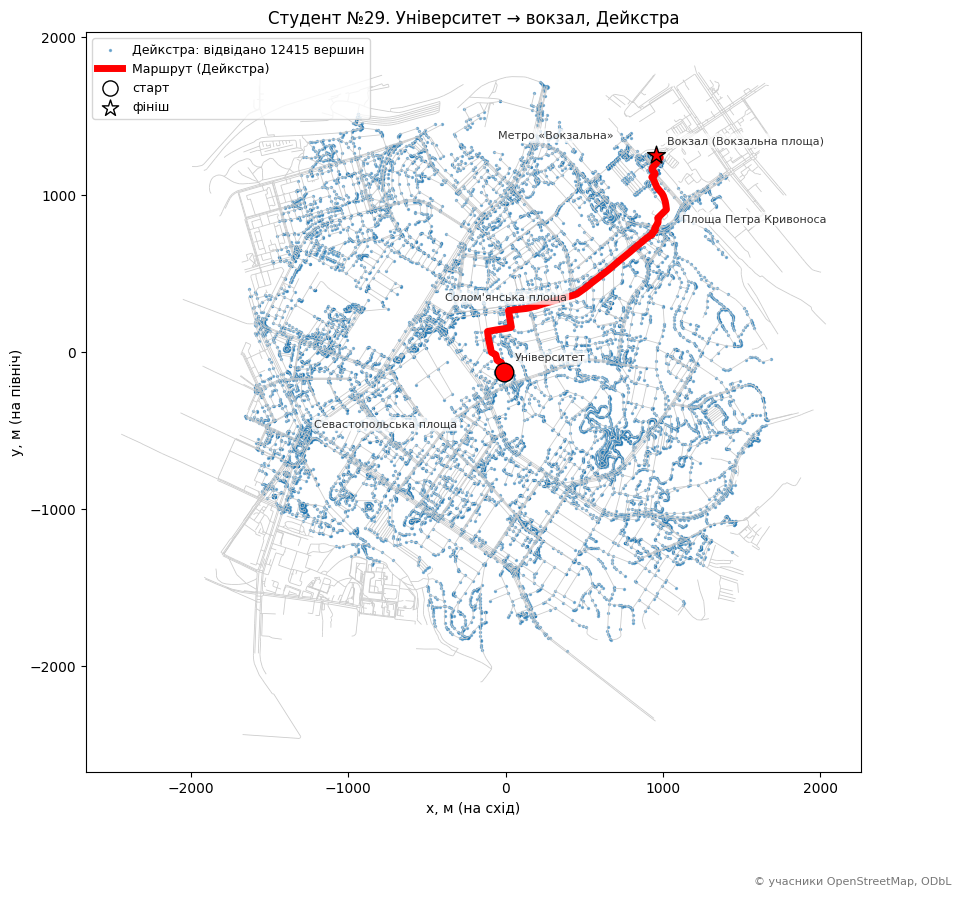

In [79]:
# 1

START, GOAL = PLACES['Університет'], PLACES['Вокзал (Вокзальна площа)']
res_d = dijkstra(GRAPH, START, GOAL)
describe(res_d, 'Дейкстра')
draw_map(routes=[('Маршрут (Дейкстра)', res_d[1], 'red')],
         visited=[('Дейкстра', res_d[2], 'tab:blue')], title='Університет → вокзал, Дейкстра')
show_on_osm(res_d[1])

A*: маршрут 2233 м, по прямій 1684 м, коефіцієнт непрямолінійності 1.33, вершин у маршруті 107, ділянок сходів 0, відвідано вершин 2108


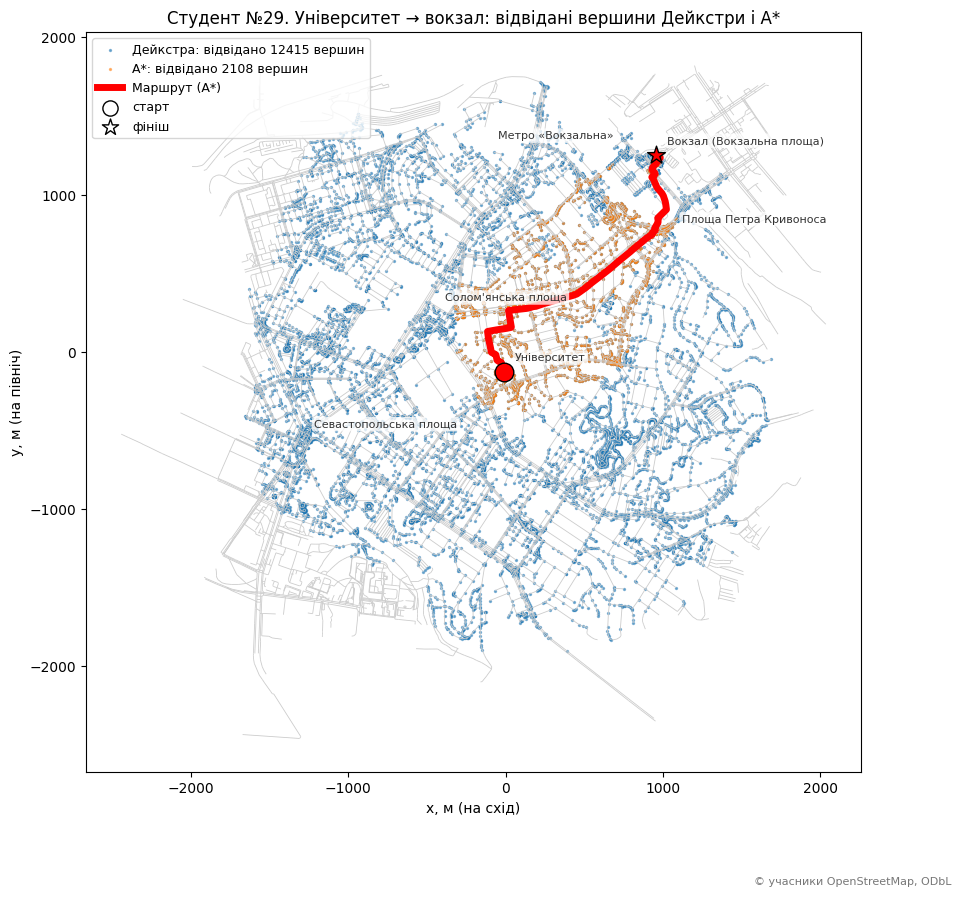

In [80]:
# 2

res_a = astar(GRAPH, START, GOAL)
describe(res_a, 'A*')
draw_map(routes=[('Маршрут (A*)', res_a[1], 'red')],
         visited=[('Дейкстра', res_d[2], 'tab:blue'), ('A*', res_a[2], 'tab:orange')],
         title='Університет → вокзал: відвідані вершини Дейкстри і A*')

Дейкстра: маршрут 1633 м, по прямій 1381 м, коефіцієнт непрямолінійності 1.18, вершин у маршруті 70, ділянок сходів 4, відвідано вершин 4925
A*: маршрут 1633 м, по прямій 1381 м, коефіцієнт непрямолінійності 1.18, вершин у маршруті 70, ділянок сходів 4, відвідано вершин 635


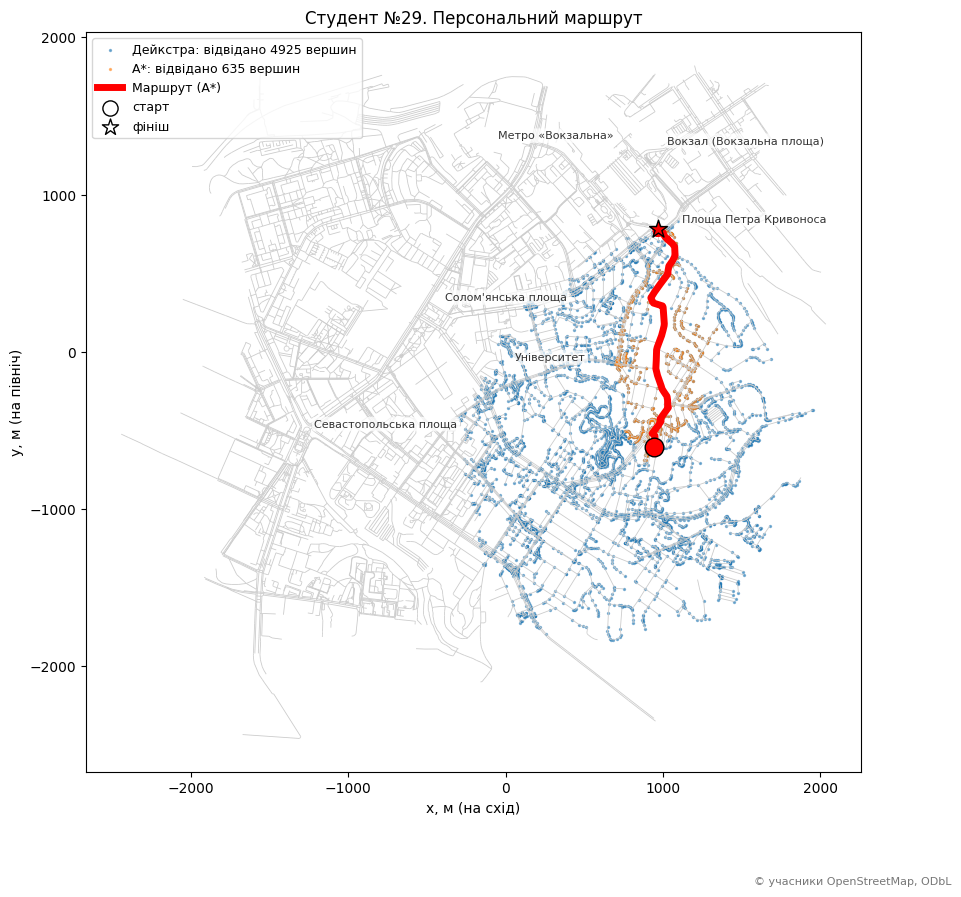

In [81]:
# 3

my_d = dijkstra(GRAPH, MY_START, MY_GOAL)
my_a = astar(GRAPH, MY_START, MY_GOAL)
describe(my_d, 'Дейкстра')
describe(my_a, 'A*')
draw_map(routes=[('Маршрут (A*)', my_a[1], 'red')],
         visited=[('Дейкстра', my_d[2], 'tab:blue'), ('A*', my_a[2], 'tab:orange')],
         title='Персональний маршрут')

In [82]:
# 4

best = my_d[0]
for w in [0, 1, 1.5, 3]:
    length, path, visited = astar(GRAPH, MY_START, MY_GOAL, h_weight=w)
    print(f'h_weight = {w:>3}: маршрут {length:.0f} м (+{100 * (length / best - 1):.1f} % до найкоротшого), '
          f'відвідано вершин {len(visited)}')

h_weight =   0: маршрут 1633 м (+0.0 % до найкоротшого), відвідано вершин 4925
h_weight =   1: маршрут 1633 м (+0.0 % до найкоротшого), відвідано вершин 635
h_weight = 1.5: маршрут 1705 м (+4.4 % до найкоротшого), відвідано вершин 94
h_weight =   3: маршрут 1751 м (+7.2 % до найкоротшого), відвідано вершин 82


In [83]:
# 5

show_on_osm(my_a[1])

Звичайний маршрут: маршрут 2087 м, по прямій 1608 м, коефіцієнт непрямолінійності 1.30, вершин у маршруті 86, ділянок сходів 3, відвідано вершин 1343
Без сходів: маршрут 2297 м, ділянок сходів 0


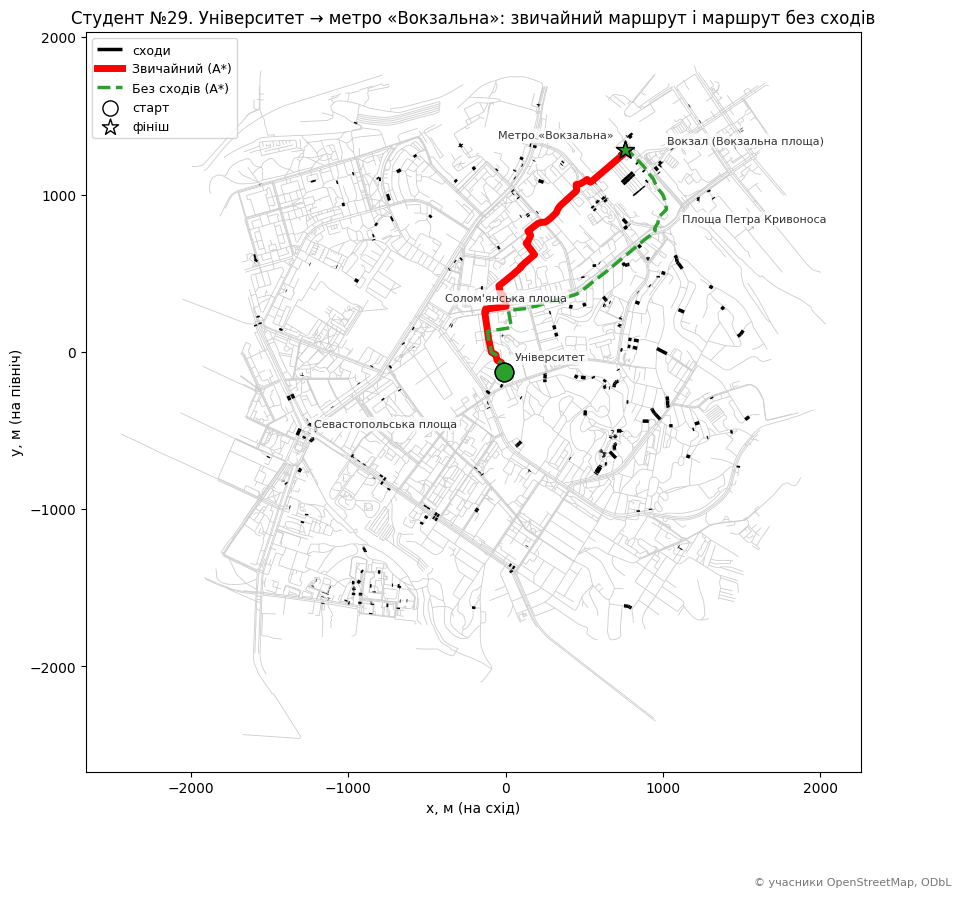

In [84]:
# 6

METRO = PLACES['Метро «Вокзальна»']
usual = astar(GRAPH, START, METRO)
no_stairs = astar(graph_with_stairs_penalty(penalty=10), START, METRO)
describe(usual, 'Звичайний маршрут')
print(f'Без сходів: маршрут {route_length(no_stairs[1]):.0f} м, '
      f'ділянок сходів {sum(tuple(sorted(e)) in STEPS for e in zip(no_stairs[1], no_stairs[1][1:]))}')
draw_map(routes=[('Звичайний (A*)', usual[1], 'red'), ('Без сходів (A*)', no_stairs[1], 'tab:green')],
         title='Університет → метро «Вокзальна»: звичайний маршрут і маршрут без сходів', show_stairs=True)